<a href="https://colab.research.google.com/github/salalisiasa-debug/-2026/blob/main/lab_06.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа № 6. Распределённое машинное обучение на Spark MLlib и исследование робототехнических датасетов

**Дисциплина:** «Методы обработки больших данных» · **Опорная лекция:** «Большие данные робототехнических и IoT-систем»

**Этап пайплайна:** `Learn → Teach` · **Среда:** Google Colab · `PySpark 4.2.0`, Spark MLlib, `RandomForestClassifier`; дополнительный блок — `LeRobotDataset`, Open X-Embodiment · **Максимум:** 10 баллов

```text
Sense → Collect → Stream → Store → Process → Learn → Teach
                                             ▲▲▲▲▲   ▲▲▲▲▲
```

**Оригинальные репозитории:** [susanli2016/PySpark-and-MLlib](https://github.com/susanli2016/PySpark-and-MLlib), [huggingface/lerobot](https://github.com/huggingface/lerobot) ([quickstart](https://github.com/huggingface/lerobot/blob/main/examples/notebooks/quickstart.ipynb)), [google-deepmind/open_x_embodiment](https://github.com/google-deepmind/open_x_embodiment) ([Colab](https://github.com/google-deepmind/open_x_embodiment/blob/main/colabs/Open_X_Embodiment_Datasets.ipynb)).

**Цель работы:** построить воспроизводимый MLlib Pipeline классификации технического состояния робота и исследовать структуру современных крупномасштабных робототехнических датасетов.

**Студенческая заготовка.** Полное описание — в `README_lab_06.md`.

### Как работать

Главное в этой работе — **не код, а понимание и выводы**: что показала модель, каким числам можно доверять и как перенести задачу в школу. Код почти весь готов; дописать нужно **8 коротких строк** (плюс ФИО и группа), и для каждой есть подсказка.

| Что видите в ячейке | Что сделать |
|---|---|
| `...` (три точки) | это **пустое место**: сотрите три точки и впишите код |
| `# ← впишите: data.randomSplit([0.8, 0.2], seed=42)` | справа после стрелки — **что именно** вписать вместо `...` (можно скопировать) |
| `Не заполнено: …` после запуска | в ячейке осталось `...`; в сообщении указано, какая строка |
| блок **«Что получено»** | дважды щёлкните по ячейке и допишите предложения-заготовки своими числами |

**Порядок:**

1. Выполните ячейку 0, затем укажите ФИО и группу в ячейке 1.
2. Выполняйте ячейки сверху вниз (**Shift + Enter**). Если ячейка остановилась с сообщением `Не заполнено`, впишите код по подсказке и запустите её снова.
3. После каждой ячейки прочитайте блок **«Как читать результат»** и заполните **«Что получено»** своими числами — это и есть основная часть отчёта.
4. Заполните `TEACH CARD` и запустите самопроверку (ячейка 9). Ячейка 10 — по желанию, после перезапуска сессии.
5. Сдайте ноутбук с сохранёнными графиками и выводами.

**Если появилась ошибка** `NameError: name '…' is not defined` — не запущена одна из **предыдущих** ячеек: выберите **Runtime → Run before** и повторите.

| Где дописать код | Что вписать |
|---|---|
| ячейка 1 | ФИО и группа |
| ячейка 2, TODO 2 | разбиение на train и test |
| ячейка 3, TODO 3.1–3.2 | сборка конвейера и его обучение |
| ячейка 4, TODO 4 | F1 класса «неисправен» |
| ячейка 6, TODO 6 | значения гиперпараметров для эксперимента |
| ячейка 8, TODO 8 | три агрегата признаков эпизода |

### Критерии оценки (10 баллов)

| Баллы | Что оценивается | Где в ноутбуке |
|---:|---|---|
| 2 | корректно подготовлены признаки, разметка и train/test split | ячейка 2 |
| 2 | корректно реализован и обучен MLlib Pipeline с Transformer/Estimator | ячейка 3 |
| 2 | рассчитаны F1/Accuracy и проведён эксперимент с гиперпараметром | ячейки 4–6 |
| 2 | исследован LeRobot или Open X-Embodiment и сделан технический вывод о структуре данных/масштабировании | ячейки 7–8 (и 10) |
| 2 | корректно заполненная форма `TEACH CARD` (педагогическая адаптация инженерной задачи) | часть «TEACH CARD» |

---

# Теоретический минимум

## Pipeline API: Transformer и Estimator

| Роль | Метод | Что делает | В работе |
|---|---|---|---|
| **Transformer** | `transform(df)` | преобразует DataFrame без обучения | `VectorAssembler`; любая обученная модель |
| **Estimator** | `fit(df)` → модель | учится на данных и возвращает Transformer | `StandardScaler` → `StandardScalerModel`, `RandomForestClassifier` → `RandomForestClassificationModel` |
| **Pipeline** | `fit(train)` → `PipelineModel` | последовательно обучает Estimator-ы **только на train** | гарантирует, что среднее и σ масштабирования не «подсмотрены» в test |

## Метрики при несбалансированных классах

$$F_1 = 2\cdot\frac{\text{Precision}\cdot\text{Recall}}{\text{Precision}+\text{Recall}}.$$

Формула задания — это F1 **одного класса** (здесь — «неисправен»). В Spark есть два разных F1:

| Вызов | Что считается |
|---|---|
| `MulticlassClassificationEvaluator(metricName="f1")` | **взвешенное** среднее F1 по классам с весами — долями классов |
| `MulticlassClassificationEvaluator(metricName="fMeasureByLabel", metricLabel=1.0)` | F1 класса 1 — формула задания |

Если неисправных объектов несколько процентов, взвешенный F1 почти совпадает с F1 класса «исправен» и выглядит высоким даже у бесполезной модели. Accuracy надо сравнивать с базовой линией «всегда исправен», а качество ранжирования оценивать по AUC ROC.

## Важность признаков

`featureImportances` случайного леса — это суммарное уменьшение нечистоты (Gini) по разбиениям признака. Метод быстрый, но **смещён**: непрерывный шумовой признак получает ненулевую важность, потому что на нём всегда можно найти «удачное» разбиение. Более честная проверка — **перестановочная важность**: перемешиваем один признак в test и смотрим, насколько упала метрика.

## Робототехнические датасеты

Единица анализа может быть **кадром** (frame), **переходом** (transition: состояние → действие → следующее состояние) или **эпизодом** (episode). LeRobot (формат v3.0) хранит таблицу кадров в Parquet (состояние, действие, награда, индексы), видео камер — отдельно в MP4, метаданные эпизодов — в отдельном Parquet. Open X-Embodiment объединяет десятки наборов в формате RLDS (эпизоды из шагов). Табличную часть естественно агрегировать в Spark, а видео — обрабатывать в deep learning-конвейере.

---
# Подготовка среды

## Ячейка 0. Установка библиотек и Java

**Что делает ячейка.**
* Ставит `pyspark==4.2.0` и недостающие пакеты.
* Проверяет версию Java: **Spark 4.x работает только на Java 17 или 21**. При более старой Java ставит OpenJDK 17.

`lerobot` здесь **не ставится**: он тянет `torch` и понижает `numpy`, поэтому вынесен в отдельную необязательную ячейку 10.

**Задание.** Ячейка готова — просто запустите (первый запуск 1–2 минуты). Java должна быть не ниже 17.

In [ ]:
import importlib.util, os, re, subprocess, sys
from importlib.metadata import version, PackageNotFoundError

def installed(dist):
    try:
        return version(dist)
    except PackageNotFoundError:
        return None

need = [] if installed("pyspark") == "4.2.0" else ["pyspark==4.2.0"]
need += [p for p in ["pandas", "numpy", "matplotlib", "huggingface_hub", "pyarrow"] if importlib.util.find_spec(p) is None]
if need:
    print("Устанавливаю:", " ".join(need))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *need])

def java_major():
    try:
        out = subprocess.run(["java", "-version"], capture_output=True, text=True).stderr
        m = re.search(r'version "(\d+)', out)
        return int(m.group(1)) if m else None
    except FileNotFoundError:
        return None

if (java_major() or 0) < 17:            # Spark 4.x работает только на Java 17/21
    print("Java", java_major(), "не подходит для Spark 4 — устанавливаю OpenJDK 17")
    subprocess.run("apt-get -qq update && apt-get -qq install -y openjdk-17-jdk-headless > /dev/null", shell=True, check=True)
    os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
    os.environ["PATH"] = os.environ["JAVA_HOME"] + "/bin:" + os.environ["PATH"]

for dist in ["pyspark", "pandas", "numpy", "huggingface_hub"]:
    print(f"{dist:<16} {installed(dist)}")
print("Java            ", java_major())

Устанавливаю: pyspark==4.2.0
pyspark          4.2.0
pandas           2.2.3
numpy            2.1.3
huggingface_hub  1.33.0
Java             21


**Что получено.** Допишите:

> Версия pyspark — 4.2.0, версия Java — 21 (Spark 4 требует Java не ниже 17: условие выполнено.

## Ячейка 1. Импорт и сессия Spark

**Что делает ячейка.** Импортирует MLlib и создаёт сессию с параметрами задания (`local[*]`, 4 shuffle-раздела). Задаёт `PYSPARK_PYTHON`, чтобы основной процесс и рабочие процессы Spark работали на одной версии Python.

**Задание.** Впишите ФИО и группу в кавычках вместо примера и запустите ячейку. Остальной код готов.

In [ ]:
import os, sys, time, math
os.environ.setdefault("PYSPARK_PYTHON", sys.executable)

# =========== ЗАПОЛНИТЕ ===========
STUDENT_NAME  = "Салимуллина Алия Дамировна"   # TODO: ← впишите свои ФИО (в кавычках)
STUDENT_GROUP = "ИНДОР-221"                  # TODO: ← впишите свою группу (в кавычках)
# =================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pyspark.sql import SparkSession, functions as F
from pyspark.ml import Pipeline, Transformer, Estimator
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.evaluation import MulticlassClassificationEvaluator, BinaryClassificationEvaluator

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, GREEN, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#9aa3ad"

spark = (
    SparkSession.builder
    .master("local[*]")
    .appName("Lab06_MLlibRobotics")
    .config("spark.sql.shuffle.partitions", "4")
    .config("spark.ui.showConsoleProgress", "false")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version, "| ядер:", spark.sparkContext.defaultParallelism)


def check_filled(where, values):
    """Проверяет, что вместо «...» вписан код; если нет — называет незаполненную строку."""
    empty = [name for name, v in values.items() if v is ...]
    if empty:
        raise ValueError(f"Не заполнено ({where}): " + ", ".join(empty)
                         + ". Замените «...» на код из подсказки «← впишите:» в этой строке и запустите ячейку снова.")

Spark 4.2.0 | ядер: 2


**Что получено.** Допишите:

> Сессия Spark версии 4.2.0 запущена в режиме `local[*]` и использует 2 ядер процессора — то есть «кластер» здесь моделируется на одном компьютере.

---
# Шаг 1. Признаки, разметка, train/test split (2 балла)

## Ячейка 2. Генерация размеченной телеметрии

**Что делает ячейка.** Генерирует 12 000 объектов **кодом и параметрами задания**: пять признаков, правило риска с весами 0,40 / 0,35 / 0,20 / 0,15 и шумом $\mathcal N(0;\,0{,}08)$, метка `risk > 0,42`, разбиение 80/20 с `seed=42`. Затем анализирует набор:
* доля неисправных;
* баланс классов в train и test;
* как часто неисправны объекты с одинаковым набором сработавших условий.

**Задание.** Генерация — код задания, параметры **не меняйте**. Допишите **одну строку** — разбиение train/test (TODO 2): `randomSplit([0.8, 0.2], seed=42)` случайно делит таблицу на две части в пропорции 80 % / 20 %; `seed=42` делает разбиение одинаковым при каждом запуске.

             условие  вес в risk  доля объектов, %
    temperature > 52        0.40              4.77
vibration_rms > 0.34        0.35              4.12
    battery_v < 11.5        0.20              7.77
     current_a > 4.0        0.15              6.85
           accel_rms        0.00               NaN

Объектов: 12000; неисправных (label = 1): 468 — 3.90 %
train: 9666 строк (3.87 % неисправных), test: 2334 строк (4.03 %)

Сочетания флагов (сумма весов) → доля неисправных:
      объектов  доля label = 1
0.00      9427           0.000
0.15       690           0.000
0.20       786           0.008
0.35       472           0.225
0.40       451           0.419
0.50        17           0.824
0.55        79           0.962
0.60        41           0.976
0.70         2           1.000
0.75        30           1.000
0.90         2           1.000
0.95         3           1.000


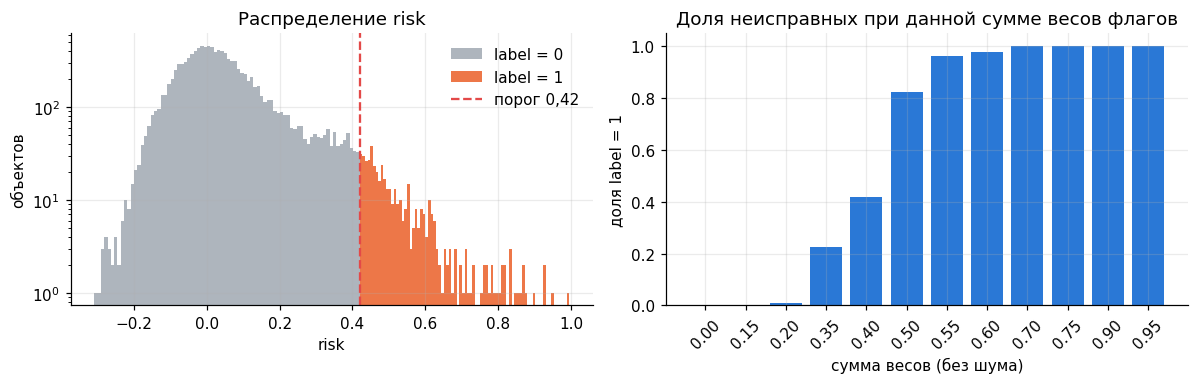

In [ ]:
# 1. Генерация размеченной телеметрии (код и параметры задания без изменений).
rng = np.random.default_rng(7)
N = 12_000

temperature = rng.normal(47, 3.0, N)
vibration_rms = np.abs(rng.normal(0.22, 0.07, N))
battery_v = rng.normal(12.0, 0.35, N)
current_a = np.abs(rng.normal(2.8, 0.8, N))
accel_rms = rng.normal(9.82, 0.18, N)

risk = (
    0.40 * (temperature > 52).astype(float)
    + 0.35 * (vibration_rms > 0.34).astype(float)
    + 0.20 * (battery_v < 11.5).astype(float)
    + 0.15 * (current_a > 4.0).astype(float)
    + rng.normal(0, 0.08, N)
)

label = (risk > 0.42).astype(int)

pdf = pd.DataFrame({
    "temperature": temperature,
    "vibration_rms": vibration_rms,
    "battery_v": battery_v,
    "current_a": current_a,
    "accel_rms": accel_rms,
    "label": label
})

data = spark.createDataFrame(pdf)
split = data.randomSplit([0.8, 0.2], seed=42)                # TODO 2 ← впишите: data.randomSplit([0.8, 0.2], seed=42)
check_filled("ячейка 2, TODO 2", {"split": split})
train, test = split    # готово: первая часть — train (80 %), вторая — test (20 %)

# --- Анализ набора ---------------------------------------------------------------
FEATURES = ["temperature", "vibration_rms", "battery_v", "current_a", "accel_rms"]
rule = pd.DataFrame({
    "условие": ["temperature > 52", "vibration_rms > 0.34", "battery_v < 11.5", "current_a > 4.0", "accel_rms"],
    "вес в risk": [0.40, 0.35, 0.20, 0.15, 0.0],
    "доля объектов, %": [(temperature > 52).mean() * 100, (vibration_rms > 0.34).mean() * 100,
                         (battery_v < 11.5).mean() * 100, (current_a > 4.0).mean() * 100, np.nan],
})
print(rule.round(2).to_string(index=False))

n_train, n_test = train.count(), test.count()
pos_train = train.agg(F.avg("label")).first()[0]; pos_test = test.agg(F.avg("label")).first()[0]
print(f"\nОбъектов: {N}; неисправных (label = 1): {label.sum()} — {label.mean() * 100:.2f} %")
print(f"train: {n_train} строк ({pos_train * 100:.2f} % неисправных), test: {n_test} строк ({pos_test * 100:.2f} %)")

# Неслучайная часть risk — то, что модель может «увидеть» по признакам; шум N(0; 0,08) не наблюдаем
det = (0.40 * (temperature > 52) + 0.35 * (vibration_rms > 0.34)
       + 0.20 * (battery_v < 11.5) + 0.15 * (current_a > 4.0))
combo = pd.Series(det).round(2).value_counts().sort_index()
p_fault = pd.Series(label).groupby(pd.Series(det).round(2)).mean()
print("\nСочетания флагов (сумма весов) → доля неисправных:")
print(pd.DataFrame({"объектов": combo, "доля label = 1": p_fault.round(3)}).to_string())

fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
axs[0].hist(risk[label == 0], bins=80, color=GREY, alpha=0.8, label="label = 0")
axs[0].hist(risk[label == 1], bins=80, color=ORANGE, alpha=0.9, label="label = 1")
axs[0].axvline(0.42, color="#e34948", ls="--", lw=1.5, label="порог 0,42")
axs[0].set(title="Распределение risk", xlabel="risk", ylabel="объектов", yscale="log"); axs[0].legend(frameon=False)
axs[1].bar([f"{v:.2f}" for v in p_fault.index], p_fault.values, color=BLUE)
axs[1].set(title="Доля неисправных при данной сумме весов флагов", xlabel="сумма весов (без шума)", ylabel="доля label = 1")
axs[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

**Как читать результат.**

* Первая таблица — правило, по которому **мы сами** разметили неисправности: чем больше вес условия, тем сильнее оно влияет на риск. У `accel_rms` вес 0 — это признак-«пустышка».
* Строки `train` / `test` показывают, сохранилась ли доля неисправных после разбиения (она должна быть близкой).
* Таблица «Сочетания флагов» и правый график: при **одном** сработавшем условии сумма весов близка к порогу 0,42, и метку решает случайный шум. При двух и более условиях объект почти всегда неисправен.

**Что получено.** Допишите своими числами:

> В наборе 12 000 объектов, неисправных 468 (3,90 %). В train 9666 строк (3,87 % неисправных), в tes 2334 строк (4,03 %) — доли классов близки / различаются.
> Признак, который не входит в правило, — accel_rms.
> При одном сработавшем условии метка случайна, потому что сумма весов условия может быть близка к порогу 0,42, а добавленный случайный шум способен изменить итоговую оценку риска и повлиять на присвоение метки неисправности.

---
# Шаг 2. MLlib Pipeline с Transformer/Estimator (2 балла)

## Ячейка 3. Сборка и обучение конвейера

**Что делает ячейка.** Собирает конвейер задания `VectorAssembler → StandardScaler → RandomForestClassifier` (80 деревьев, глубина 8) и обучает его на train. Затем показывает, какой стадией была каждая часть до `fit()` и чем стала после.

**Задание.** Допишите **две строки** (TODO 3.1–3.2): соберите конвейер из трёх готовых стадий и обучите его на train.

* `Pipeline(stages=[…])` — «конвейер»: стадии выполняются по порядку, как станки на линии.
* `pipeline.fit(train)` — обучение: каждая стадия-Estimator учится **только на train** и превращается в готовую модель.

In [ ]:
# 2. Pipeline: Transformer -> Estimator -> Transformer -> Estimator (код задания).
assembler = VectorAssembler(
    inputCols=["temperature", "vibration_rms", "battery_v", "current_a", "accel_rms"],
    outputCol="raw_features"
)

scaler = StandardScaler(
    inputCol="raw_features",
    outputCol="features",
    withMean=True,
    withStd=True
)

rf = RandomForestClassifier(
    labelCol="label",
    featuresCol="features",
    numTrees=80,
    maxDepth=8,
    seed=42
)

pipeline = Pipeline(stages=[assembler, scaler, rf])
             # TODO 3.1 ← впишите: Pipeline(stages=[assembler, scaler, rf])

t0 = time.time()
model =  pipeline.fit(train)                # TODO 3.2 ← впишите: pipeline.fit(train)
fit_s = time.time() - t0
check_filled("ячейка 3, TODO 3.1–3.2", {"pipeline": pipeline, "model": model})
pred = model.transform(test)

# Какие стадии — Transformer, а какие — Estimator, до и после fit()
roles = pd.DataFrame([{"стадия": type(s).__name__,
                       "до fit()": "Estimator" if isinstance(s, Estimator) else "Transformer",
                       "после fit()": type(m).__name__ + (" (Transformer)" if isinstance(m, Transformer) else "")}
                      for s, m in zip(pipeline.getStages(), model.stages)])
print(roles.to_string(index=False))
print(f"\nОбучение конвейера: {fit_s:.1f} с; деревьев в лесу: {model.stages[-1].getNumTrees}")
sc = model.stages[1]
print("StandardScaler, выученные на train средние:", np.round(sc.mean.toArray(), 3))
print("StandardScaler, выученные на train σ:      ", np.round(sc.std.toArray(), 3))

                стадия    до fit()                                   после fit()
       VectorAssembler Transformer                 VectorAssembler (Transformer)
        StandardScaler   Estimator             StandardScalerModel (Transformer)
RandomForestClassifier   Estimator RandomForestClassificationModel (Transformer)

Обучение конвейера: 25.9 с; деревьев в лесу: 80
StandardScaler, выученные на train средние: [46.945  0.22  11.996  2.802  9.82 ]
StandardScaler, выученные на train σ:       [2.998 0.069 0.349 0.794 0.18 ]


**Как читать результат.**

* Таблица ролей: **Estimator** — то, что учится на данных (`fit`), **Transformer** — то, что только преобразует таблицу (`transform`). После обучения каждый Estimator превращается в модель-Transformer.
* Средние и σ StandardScaler посчитаны по train: test в обучении не участвовал, поэтому оценка качества на test честная.

**Что получено.** Допишите:

> До `fit()` Estimator-ами были StandardScaler и  RandomForestClassifier, а Transformer-ом — VectorAssembler. После `fit()` они стали StandardScalerModel и StandardScalerModel.
> Обучение заняло 25,9 с. Статистики масштабирования считаются только на train, потому что использование test при обучении привело бы к утечке данных и сделало оценку качества модели менее объективной.

---
# Шаг 3. F1 и Accuracy

## Ячейка 4. Метрики задания и их смысл

**Что делает ячейка.** Считает F1 и Accuracy **кодом задания**. Затем выясняет, что именно измеряет этот F1, и сравнивает модель с двумя ориентирами:
* базовая линия «всегда исправен»;
* **оракул**, который знает правило генерации, но не знает шум (лучшее, что возможно по этим признакам при пороге 0,5).

**Задание.** Допишите **одну строку** (TODO 4): F1 класса «неисправен». Готовая функция `by_label("имя метрики")` считает метрику для класса 1; precision и recall в соседней строке посчитаны так же — используйте их как образец.

In [ ]:
evaluator_f1 = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="f1")
evaluator_acc = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="accuracy")

f1 = evaluator_f1.evaluate(pred)
acc = evaluator_acc.evaluate(pred)

print(f"F1       = {f1:.4f}")
print(f"Accuracy = {acc:.4f}")

pred.select("temperature", "vibration_rms", "battery_v", "label", "prediction", "probability").show(5, truncate=False)

# --- Что на самом деле означает этот F1 ------------------------------------------------
def by_label(metric, lab=1.0):
    return MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction",
                                             metricName=metric, metricLabel=lab).evaluate(pred)

p1, r1 = by_label("precisionByLabel"), by_label("recallByLabel")
f1_pos = by_label("fMeasureByLabel")              # TODO 4 ← впишите: by_label("fMeasureByLabel")
check_filled("ячейка 4, TODO 4", {"f1_pos": f1_pos})
f1_neg = by_label("fMeasureByLabel", 0.0)
auc = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="rawPrediction").evaluate(pred)
cm = pred.groupBy("label", "prediction").count().toPandas().pivot(index="label", columns="prediction", values="count").fillna(0).astype(int)

tp_ = test.select(*FEATURES, "label").toPandas()
det_test = (0.40 * (tp_.temperature > 52) + 0.35 * (tp_.vibration_rms > 0.34)
            + 0.20 * (tp_.battery_v < 11.5) + 0.15 * (tp_.current_a > 4.0))
oracle = (det_test > 0.42).astype(int)                      # знает правило, но не знает шум
def binf1(y, p):
    tp, fp, fn = ((p == 1) & (y == 1)).sum(), ((p == 1) & (y == 0)).sum(), ((p == 0) & (y == 1)).sum()
    P = tp / (tp + fp) if tp + fp else 0.0; R = tp / (tp + fn) if tp + fn else 0.0
    return P, R, (2 * P * R / (P + R) if P + R else 0.0)

base_acc = 1 - pos_test
oP, oR, oF = binf1(tp_.label.values, oracle.values)
quality = pd.DataFrame([
    {"модель": "RandomForest (задание)", "accuracy": acc, "F1 взвешенный": f1, "F1 класса 1": f1_pos, "precision 1": p1, "recall 1": r1},
    {"модель": "«всегда исправен»", "accuracy": base_acc, "F1 взвешенный": base_acc * (2 * base_acc / (1 + base_acc)),
     "F1 класса 1": 0.0, "precision 1": np.nan, "recall 1": 0.0},
    {"модель": "оракул: точное правило без шума", "accuracy": (oracle.values == tp_.label.values).mean(), "F1 взвешенный": np.nan,
     "F1 класса 1": oF, "precision 1": oP, "recall 1": oR},
])
print("\nМатрица ошибок (строки — истина, столбцы — прогноз):"); print(cm)
print(f"\nF1 класса 0 = {f1_neg:.4f}, F1 класса 1 = {f1_pos:.4f}; доли классов в test: {1 - pos_test:.3f} / {pos_test:.3f}")
print(f"Взвешенное среднее: {(1 - pos_test) * f1_neg + pos_test * f1_pos:.4f} — это и есть metricName='f1'")
print(f"AUC ROC = {auc:.4f}\n"); print(quality.round(4).to_string(index=False))

assert f1 > 0.75          # проверка задания: выполняется, потому что F1 — взвешенный по классам

F1       = 0.9622
Accuracy = 0.9666
+------------------+-------------------+------------------+-----+----------+------------------------------------------+
|temperature       |vibration_rms      |battery_v         |label|prediction|probability                               |
+------------------+-------------------+------------------+-----+----------+------------------------------------------+
|36.64481573322119 |0.17385619496355464|11.74422327970953 |0    |0.0       |[0.9997319872822444,2.680127177554584E-4] |
|37.66590998953893 |0.28256121606266993|12.141699887592662|0    |0.0       |[0.9997148478387876,2.851521612124705E-4] |
|37.74695869974583 |0.14507019369690505|12.33269991531806 |0    |0.0       |[0.9997818665500562,2.181334499438957E-4] |
|38.550817274767795|0.20664485958282391|11.688454025329655|0    |0.0       |[0.9998031449082113,1.9685509178878015E-4]|
|38.88221781474054 |0.39331658469986736|11.94388243186343 |0    |0.0       |[0.7190547303161544,0.2809452696838455]   |
+---

**Как читать результат.**

* **Accuracy** — доля верных ответов. Если неисправных всего ≈ 4 %, модель, которая **всегда** отвечает «исправен», уже получит ≈ 96 %. Поэтому accuracy сравниваем с этой базовой линией.
* **F1 задания** (`metricName="f1"`) — среднее F1 двух классов **с весами по их долям**: он почти равен F1 класса «исправен» и поэтому высокий.
* **F1 класса 1**, **precision** и **recall** — насколько хорошо модель находит именно неисправности: precision — какая доля тревог настоящая, recall — какую долю неисправных модель нашла.
* **Матрица ошибок**: строка — истина, столбец — прогноз. Ячейка «истина 1, прогноз 0» — пропущенные неисправности, самая опасная ошибка для робота.
* **Оракул** знает правило, но не знает шум: его результат — потолок, выше которого по этим признакам не прыгнуть.

**Что получено.** Допишите своими числами:

> F1 задания = 0,9622, Accuracy = 0,9666; у модели «всегда исправен» Accuracy =  0,9597.
> F1 класса «неисправен» = 0,4730 (precision 0,6481, recall 0,3723): модель находит примерно 4 из 10 неисправностей.
> Пропущено неисправностей (истина 1, прогноз 0): 59. F1 задания высокий, а F1 класса 1 низкий, потому что исправных объектов значительно больше (96%), и взвешенный F1 в основном отражает качество распознавания исправного состояния.
> Оракул получил F1 класса 1 =  0,5156; значит, часть ошибок модели неустранима, потому что при создании меток использовался случайный шум, который модель не может наблюдать и учитывать при прогнозировании.

---
# Шаг 4. Важность признаков и правило генерации

## Ячейка 5. featureImportances против весов правила

**Что делает ячейка.** Сопоставляет `featureImportances` с весами правила и считает перестановочную важность (падение AUC на test).

**Задание.** Ячейка готова — просто запустите и сравните три графика: вес в правиле, важность по мнению леса и перестановочную важность.

Feature importances: (5,[0,1,2,3,4],[0.4608072418248801,0.20519258643324295,0.12328154517303389,0.12690424167018682,0.08381438489865627])
      признак  важность RF  вес в правиле  падение AUC при перестановке
  temperature       0.4608           0.40                        0.2234
vibration_rms       0.2052           0.35                        0.1147
    battery_v       0.1233           0.20                        0.0187
    current_a       0.1269           0.15                        0.0046
    accel_rms       0.0838           0.00                       -0.0003


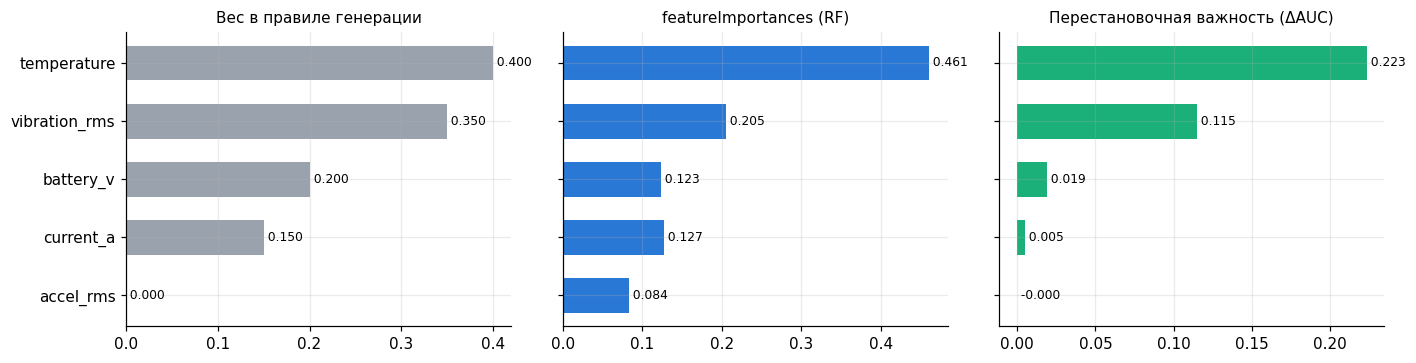

In [ ]:
rf_model = model.stages[-1]
print("Feature importances:", rf_model.featureImportances)

imp = pd.DataFrame({"признак": FEATURES, "важность RF": rf_model.featureImportances.toArray(),
                    "вес в правиле": [0.40, 0.35, 0.20, 0.15, 0.0]})

# Перестановочная важность: насколько падает AUC на test, если перемешать один признак
def auc_on(pdf_):
    return BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="rawPrediction").evaluate(
        model.transform(spark.createDataFrame(pdf_)))
base_auc = auc_on(tp_)
perm = []
for col in FEATURES:
    shuffled = tp_.copy(); shuffled[col] = np.random.default_rng(0).permutation(shuffled[col].values)
    perm.append(base_auc - auc_on(shuffled))
imp["падение AUC при перестановке"] = perm
print(imp.round(4).to_string(index=False))

fig, axs = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
y = np.arange(len(FEATURES))
for ax, col, color, title in zip(axs, ["вес в правиле", "важность RF", "падение AUC при перестановке"],
                                 [GREY, BLUE, GREEN], ["Вес в правиле генерации", "featureImportances (RF)", "Перестановочная важность (ΔAUC)"]):
    ax.barh(y, imp[col], color=color, height=0.6); ax.set_title(title, fontsize=10)
    for yy, v in zip(y, imp[col]):
        ax.text(v, yy, f" {v:.3f}", va="center", fontsize=8)
axs[0].set_yticks(y); axs[0].set_yticklabels(FEATURES); axs[0].invert_yaxis()
plt.tight_layout(); plt.show()

**Как читать результат.**

* **featureImportances** — насколько часто и успешно лес «разрезал» данные по признаку. Метод быстрый, но любит непрерывные признаки и может дать важность даже шуму.
* **Перестановочная важность** — перемешиваем один признак в test и смотрим, сколько теряет AUC. Если почти ничего — модель этим признаком на деле не пользуется.

**Что получено.** Допишите своими числами:

> Самый важный признак по мнению леса — temperature (0,4608), это совпадает / не совпадает с наибольшим весом в правиле (0,40).
> Порядок признаков по важности:temperature → vibration_rms → current_a → battery_v → accel_rms  — он совпадает с весами правила частично.
> `accel_rms` получил featureImportance 0,0838, хотя в правиле не участвует, потому что случайный лес может использовать даже неинформативные признаки при построении деревьев, приписывая им некоторую важность из-за случайных особенностей обучающих данных. Перестановочная важность `accel_rms` = −0,0003, то есть перемешивание этого признака практически не влияет на качество модели (AUC), и он не приносит реальной пользы для обнаружения неисправностей.

---
# Шаг 5. Эксперимент с гиперпараметрами

## Ячейка 6. numTrees, maxDepth, масштабирование, порог, веса классов

**Что делает ячейка.**
* Меняет по одному гиперпараметру (`numTrees` при глубине 8, `maxDepth` при 80 деревьях) и сравнивает три метрики.
* Проверяет, нужен ли лесу `StandardScaler`.
* Показывает два способа действительно улучшить обнаружение неисправностей: порог вероятности и веса классов.

**Задание.** Допишите **список пар** `(numTrees, maxDepth)` (TODO 6): не меньше трёх значений `numTrees` при `maxDepth = 8` и трёх значений `maxDepth` при `numTrees = 80`. Можно взять пары из подсказки или свои. Каждая пара — одно обучение леса, поэтому ячейка работает 1–3 минуты.

* `numTrees` — сколько деревьев голосуют (больше — устойчивее, но дольше);
* `maxDepth` — сколько вопросов подряд может задать одно дерево (больше — сложнее правила, выше риск переобучения).

 numTrees  maxDepth  F1 взвешенный  F1 класса 1  recall 1    AUC  обучение, с
       10         8         0.9631       0.4901    0.3936 0.9703       4.9616
       40         8         0.9622       0.4730    0.3723 0.9714       8.0001
       80         8         0.9622       0.4730    0.3723 0.9710       6.9604
      160         8         0.9642       0.5000    0.3936 0.9714      11.1621
       80         2         0.9421       0.0417    0.0213 0.9720       4.5685
       80         4         0.9646       0.4677    0.3085 0.9725       3.9824
       80        12         0.9594       0.4568    0.3936 0.9589       9.5686

Без StandardScaler совпадает 100.0 % прогнозов

Порог вероятности класса 1 (модель задания):
 порог  precision 1  recall 1  F1 класса 1
  0.50        0.648     0.372        0.473
  0.40        0.557     0.468        0.509
  0.30        0.462     0.638        0.536
  0.25        0.418     0.702        0.524
  0.20        0.369     0.777        0.500
  0.15        0.356     

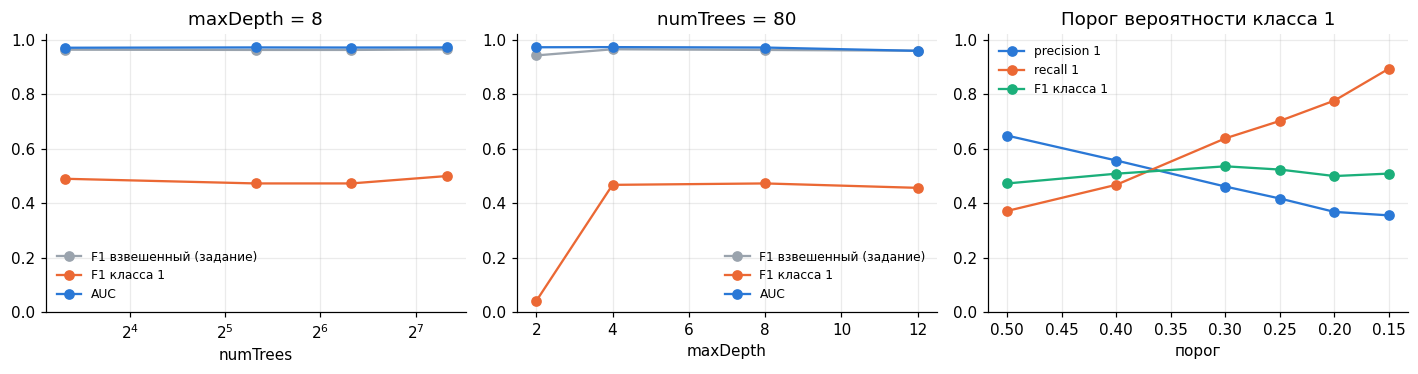

In [ ]:
# Эксперимент с гиперпараметрами: каждый раз меняется один параметр
def run(num_trees, max_depth, train_df=train, weight_col=None, use_scaler=True):
    feats = "features" if use_scaler else "raw_features"
    clf = RandomForestClassifier(labelCol="label", featuresCol=feats, numTrees=num_trees, maxDepth=max_depth, seed=42)
    if weight_col:
        clf = clf.setWeightCol(weight_col)
    stages = [assembler, scaler, clf] if use_scaler else [assembler, clf]
    t0 = time.time(); m = Pipeline(stages=stages).fit(train_df); sec = time.time() - t0
    p = m.transform(test)
    ev = lambda name, **kw: MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName=name, **kw).evaluate(p)
    return m, p, {"numTrees": num_trees, "maxDepth": max_depth, "F1 взвешенный": ev("f1"),
                  "F1 класса 1": ev("fMeasureByLabel", metricLabel=1.0), "recall 1": ev("recallByLabel", metricLabel=1.0),
                  "AUC": BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="rawPrediction").evaluate(p),
                  "обучение, с": sec}

grid = [(10, 8), (40, 8), (80, 8), (160, 8), (80, 2), (80, 4), (80, 12)]                # TODO 6 ← впишите, например: [(10, 8), (40, 8), (80, 8), (160, 8), (80, 2), (80, 4), (80, 12)]
check_filled("ячейка 6, TODO 6", {"grid": grid})
assert len({nt for nt, md in grid if md == 8}) >= 3 and len({md for nt, md in grid if nt == 80}) >= 3, \
    "TODO 6: нужно ≥ 3 разных numTrees при maxDepth = 8 и ≥ 3 разных maxDepth при numTrees = 80"
hp = pd.DataFrame([run(nt, md)[2] for nt, md in grid])
print(hp.round(4).to_string(index=False))

# Нужен ли StandardScaler случайному лесу?
_, p_noscale, _ = run(80, 8, use_scaler=False)
same = (p_noscale.select("prediction").toPandas().prediction.values == pred.select("prediction").toPandas().prediction.values).mean()
print(f"\nБез StandardScaler совпадает {same * 100:.1f} % прогнозов")

# Что реально помогает классу 1: порог вероятности и веса классов
prob1 = np.array([v[1] for v in pred.select("probability").toPandas().probability])
y_test = pred.select("label").toPandas().label.values
thr = pd.DataFrame([dict(порог=t, **dict(zip(["precision 1", "recall 1", "F1 класса 1"], binf1(y_test, (prob1 >= t).astype(int)))))
                    for t in [0.5, 0.4, 0.3, 0.25, 0.2, 0.15]])
print("\nПорог вероятности класса 1 (модель задания):"); print(thr.round(3).to_string(index=False))
w_pos = (1 - pos_train) / pos_train
train_w = train.withColumn("w", F.when(F.col("label") == 1, F.lit(w_pos)).otherwise(F.lit(1.0)))
_, _, weighted = run(80, 8, train_df=train_w, weight_col="w")
print(f"\nВеса классов (w₁ = {w_pos:.1f}): F1 класса 1 = {weighted['F1 класса 1']:.3f}, recall = {weighted['recall 1']:.3f}, "
      f"F1 взвешенный = {weighted['F1 взвешенный']:.4f}")

fig, axs = plt.subplots(1, 3, figsize=(13, 3.5))
d1 = hp[hp.maxDepth == 8]; d2 = hp[hp.numTrees == 80]
for ax, d, x, title in ((axs[0], d1.sort_values("numTrees"), "numTrees", "maxDepth = 8"),
                        (axs[1], d2.sort_values("maxDepth"), "maxDepth", "numTrees = 80")):
    ax.plot(d[x], d["F1 взвешенный"], "o-", color=GREY, label="F1 взвешенный (задание)")
    ax.plot(d[x], d["F1 класса 1"], "o-", color=ORANGE, label="F1 класса 1")
    ax.plot(d[x], d["AUC"], "o-", color=BLUE, label="AUC")
    ax.set(title=title, xlabel=x, ylim=(0, 1.02)); ax.legend(frameon=False, fontsize=8)
axs[0].set_xscale("log", base=2)
axs[2].plot(thr["порог"], thr["precision 1"], "o-", color=BLUE, label="precision 1")
axs[2].plot(thr["порог"], thr["recall 1"], "o-", color=ORANGE, label="recall 1")
axs[2].plot(thr["порог"], thr["F1 класса 1"], "o-", color=GREEN, label="F1 класса 1")
axs[2].set(title="Порог вероятности класса 1", xlabel="порог", ylim=(0, 1.02)); axs[2].invert_xaxis(); axs[2].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

**Как читать результат.**

* Левый и средний графики: как меняются три метрики при изменении **одного** параметра. Серая линия (F1 задания) почти не двигается — по ней разницу между моделями не увидеть; смотрите на оранжевую (F1 класса 1) и синюю (AUC).
* «Без StandardScaler совпадает … % прогнозов»: дереву не важен масштаб признака — оно сравнивает значение с порогом.
* Правый график — **порог вероятности**: чем ниже порог, тем больше тревог (recall растёт), но больше и ложных (precision падает). **Веса классов** заставляют лес «внимательнее» относиться к редким неисправностям.

**Что получено.** Допишите своими числами:

> При росте `numTrees` от 10 до 160 F1 класса 1 изменился с 0,4901 до 0,5000, AUC — с 0,9703 до 0,9714: эффект слабый.
> При `maxDepth` = 2 F1 класса 1 = 0,0417, при 8 — 0,4730: слишком мелкие деревья плохо распознают редкие неисправности, поскольку не могут учитывать сложные сочетания признаков.
> Без StandardScaler совпадает 100 % прогнозов, значит для случайного леса масштабирование признаков в данном случае не влияет на результат.
> При пороге 0,30 recall вырос до 0,638, F1 класса 1 — до 0,536. Веса классов дали F1 класса 1 = 0,592 и recall 0,894.
> Для робота важнее не пропустить неисправность, поэтому я бы выбрала модель с весами классов, поскольку она обнаруживает 89,4% неисправностей и показывает лучший F1 класса 1 среди проверенных вариантов.

---
# Шаг 6. Исследование робототехнического датасета (2 балла вместе с шагом 7)

## Ячейка 7. Структура `lerobot/pusht`

**Что делает ячейка.** Скачивает с Hugging Face Hub **только** метаданные и таблицы набора `lerobot/pusht` (≈ 0,8 МБ, без видео) и фиксирует число эпизодов, кадров и признаков. Затем оценивает, сколько места заняли бы кадры камеры по сравнению с табличными данными. Это лёгкий путь, который работает в той же сессии, что и Spark. Официальный путь через `LeRobotDataset` — в ячейке 10.

**Задание.** Ячейка готова — просто запустите и зафиксируйте число episodes, frames и features.

**Словарик:** *episode* — одна попытка робота выполнить задачу от начала до конца; *frame* — один момент времени (кадр) внутри попытки; *feature* — что записано в каждом кадре (положение, действие, изображение камеры, награда…).

In [ ]:
# Шаг 6. Структура реального robotics dataset: lerobot/pusht (формат LeRobot v3.0)
import json
from huggingface_hub import hf_hub_download

REPO = "lerobot/pusht"
info = json.load(open(hf_hub_download(REPO, "meta/info.json", repo_type="dataset")))
frames_pq = hf_hub_download(REPO, "data/chunk-000/file-000.parquet", repo_type="dataset")
episodes_pq = hf_hub_download(REPO, "meta/episodes/chunk-000/file-000.parquet", repo_type="dataset")

print(f"Формат: {info['codebase_version']}, fps = {info['fps']}")
print(f"Episodes: {info['total_episodes']}   Frames: {info['total_frames']}   Tasks: {info['total_tasks']}")
feat = pd.DataFrame([{"признак": k, "тип": v["dtype"], "форма": tuple(v["shape"])} for k, v in info["features"].items()])
print(feat.to_string(index=False))
print("\nРазмер файлов:", f"таблица кадров {os.path.getsize(frames_pq) / 1e6:.2f} МБ,",
      f"метаданные эпизодов {os.path.getsize(episodes_pq) / 1e6:.2f} МБ")

img = info["features"]["observation.image"]["shape"]
raw_px = info["total_frames"] * int(np.prod(img))
state_bytes = info["total_frames"] * (2 + 2) * 4
print(f"Несжатые кадры камеры: {info['total_frames']} × {img[0]}×{img[1]}×{img[2]} байт = {raw_px / 1e6:.0f} МБ; "
      f"состояние + действие: {state_bytes / 1e6:.2f} МБ — в {raw_px / state_bytes:.0f} раз меньше")

info.json:   0%|          | 0.00/2.26k [00:00<?, ?B/s]

data/chunk-000/file-000.parquet: reconstructing file:   0%|          |  0.00B /  674kB            

data/chunk-000/file-000.parquet: downloading bytes:           |  0.00B            

meta/episodes/chunk-000/file-000.parquet: reconstructing file:   0%|          |  0.00B /  107kB            

meta/episodes/chunk-000/file-000.parquet: downloading bytes:           |  0.00B            

Формат: v3.0, fps = 10
Episodes: 206   Frames: 25650   Tasks: 1
          признак     тип       форма
observation.image   video (96, 96, 3)
observation.state float32        (2,)
           action float32        (2,)
    episode_index   int64        (1,)
      frame_index   int64        (1,)
        timestamp float32        (1,)
      next.reward float32        (1,)
        next.done    bool        (1,)
     next.success    bool        (1,)
            index   int64        (1,)
       task_index   int64        (1,)

Размер файлов: таблица кадров 0.67 МБ, метаданные эпизодов 0.11 МБ
Несжатые кадры камеры: 25650 × 96×96×3 байт = 709 МБ; состояние + действие: 0.41 МБ — в 1728 раз меньше


**Как читать результат.**

* Таблица признаков: `observation.state` — где находится агент, `action` — куда ему велели двигаться, `observation.image` — кадр камеры, `next.reward` и `next.success` — насколько хорошо выполнена задача.
* Последняя строка сравнивает объём «картинок» и «чисел»: именно поэтому видео хранят отдельно, а таблицу — в Parquet.

**Что получено.** Допишите своими числами:

> В наборе `lerobot/pusht` 206 эпизодов, 25 650 кадров, частота 10  кадров/с, 11 признаков.
> Табличные признаки: observation.state, action, episode_index, frame_index, timestamp, next.reward, next.done, next.success, index, task_index; изображение: observation.image  размером 96 × 96 × 3.
> Несжатые кадры камеры занимают 709 МБ — в 1728 раз больше, чем состояние и действие.

## Ячейка 8. Что агрегировать в Spark

**Что делает ячейка.** Читает таблицу кадров `pusht` в Spark и строит **признаки эпизодов**: число кадров, длительность, путь агента (сумма перемещений по `observation.state`), среднее отклонение действия от состояния, максимальная награда, флаг успеха. Это ответ на шаг 7 задания на реальных данных, а не на словах.

**Задание.** Допишите **три строки** (TODO 8) — три агрегата для каждого эпизода. Три других агрегата уже написаны — используйте их как образец:

| Функция Spark | Что считает | Пример |
|---|---|---|
| `F.count("*")` | сколько строк (кадров) | готово |
| `F.max("столбец")` | максимум | готово для длительности |
| `F.sum("столбец")` | сумма | путь агента = сумма шагов `step` |
| `F.avg("столбец")` | среднее | среднее отклонение `lag_err` |

`.alias("имя")` задаёт название столбца в результате — пишите названия **точно как в подсказке**: по ним строятся графики.

root
 |-- observation.state: array (nullable = true)
 |    |-- element: float (containsNull = true)
 |-- action: array (nullable = true)
 |    |-- element: float (containsNull = true)
 |-- episode_index: long (nullable = true)
 |-- frame_index: long (nullable = true)
 |-- timestamp: float (nullable = true)
 |-- next.reward: float (nullable = true)
 |-- next.done: boolean (nullable = true)
 |-- next.success: boolean (nullable = true)
 |-- index: long (nullable = true)
 |-- task_index: long (nullable = true)

       episode_index  кадров  длительность, с  путь агента  откл. действие–состояние  макс. награда  успех
count         206.00  206.00           206.00       206.00                    206.00         206.00  206.0
mean          102.50  124.51            12.35      1168.36                     23.24           0.89    0.0
std            59.61   35.67             3.57       419.79                      4.54           0.03    0.0
min             0.00   49.00             4.80       371.92 

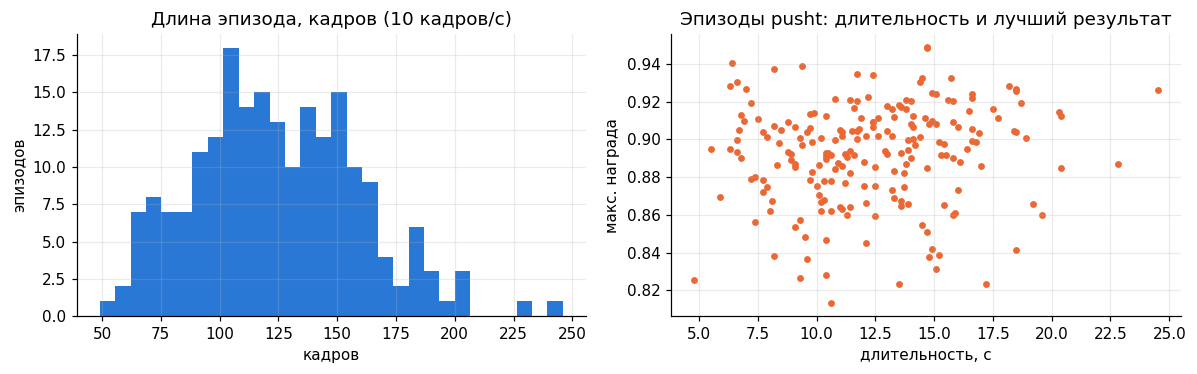

In [ ]:
# Шаг 7. Что из robotics dataset агрегировать в Spark: таблица кадров → признаки эпизодов
frames = spark.read.parquet(frames_pq)
frames.printSchema()

w = F.col
ep = (frames
      .select("episode_index", "frame_index", "timestamp",
              w("`observation.state`")[0].alias("x"), w("`observation.state`")[1].alias("y"),
              w("action")[0].alias("ax"), w("action")[1].alias("ay"),
              w("`next.reward`").alias("reward"), w("`next.success`").alias("success")))
from pyspark.sql import Window
wo = Window.partitionBy("episode_index").orderBy("frame_index")
ep = (ep.withColumn("step", F.sqrt((w("x") - F.lag("x").over(wo)) ** 2 + (w("y") - F.lag("y").over(wo)) ** 2))
        .withColumn("lag_err", F.sqrt((w("ax") - w("x")) ** 2 + (w("ay") - w("y")) ** 2)))
# TODO 8. Три агрегата признаков эпизода (остальные три уже готовы — см. ниже)
agg_path   = F.sum("step").alias("путь агента")   # ← впишите: F.sum("step").alias("путь агента")
agg_err    = F.avg("lag_err").alias("откл. действие–состояние")   # ← впишите: F.avg("lag_err").alias("откл. действие–состояние")
agg_reward = F.max("reward").alias("макс. награда")  # ← впишите: F.max("reward").alias("макс. награда")
check_filled("ячейка 8, TODO 8", {"agg_path": agg_path, "agg_err": agg_err, "agg_reward": agg_reward})

episodes = (ep.groupBy("episode_index")                          # одна строка результата = один эпизод
            .agg(F.count("*").alias("кадров"),                    # готово: число кадров
                 F.max("timestamp").alias("длительность, с"),     # готово: время последнего кадра
                 agg_path, agg_err, agg_reward,                   # ваши три агрегата
                 F.max(F.col("success").cast("int")).alias("успех")))   # готово: был ли успех
ep_pdf = episodes.toPandas()
print(ep_pdf.describe().round(2).to_string())
print(f"\nЭпизодов с флагом успеха: {int(ep_pdf['успех'].sum())} из {len(ep_pdf)}; "
      f"максимальная награда в наборе {ep_pdf['макс. награда'].max():.3f}")
print(f"Корреляция «длительность — макс. награда»: {ep_pdf['длительность, с'].corr(ep_pdf['макс. награда']):.2f}")

fig, axs = plt.subplots(1, 2, figsize=(11, 3.5))
axs[0].hist(ep_pdf["кадров"], bins=30, color=BLUE)
axs[0].set(title="Длина эпизода, кадров (10 кадров/с)", xlabel="кадров", ylabel="эпизодов")
axs[1].scatter(ep_pdf["длительность, с"], ep_pdf["макс. награда"], s=12, color=ORANGE)
axs[1].set(title="Эпизоды pusht: длительность и лучший результат", xlabel="длительность, с", ylabel="макс. награда")
plt.tight_layout(); plt.show()

**Как читать результат.**

* Таблица `describe`: `count` — число эпизодов, `mean` — среднее, `min` / `max` — крайние значения, `50%` — медиана.
* Миллионы кадров удобно «сжимать» в Spark до одной строки на эпизод: длина, путь, награда, успех — такую таблицу уже можно анализировать и даже обучать на ней MLlib.
* Видео так не агрегируется: из кадра нельзя посчитать «среднее» — изображения обрабатывают нейросетями (deep learning) отдельно.

**Что получено.** Допишите своими числами:

> Эпизод длится в среднем 124,51 кадров (12,35  с), от 49  до 246 кадров. Средний путь агента — 1168,36, средняя максимальная награда — 0,89.
> Успехом закончились 0 из 206 эпизодов. Корреляция «длительность — награда» = 0,12, то есть связь очень слабая: более длительный эпизод не обязательно приносит большую награду.
> В Spark целесообразно агрегировать числовые показатели каждого эпизода(длительность, пройденный путь, награду и признак успеха), потому что это позволяет сократить большой набор измерений до компактной таблицы для анализа. Не стоит переносить в Spark MLlib сами изображения с камеры, потому что для их обработки нужны специализированные методы компьютерного зрения и нейросети, а Spark MLlib в данной лабораторной используется для анализа табличных признаков.

## Ячейка 9. Самопроверка

**Что делает ячейка.** Проверяет наличие обязательных результатов. Это «предполётный контроль», а не оценка.

**Задание.** Ячейка готова — просто запустите. Все пункты должны быть `OK`; если где-то `НЕТ`, вернитесь к названной ячейке.

In [ ]:
checks = {
    "Заполнены ФИО и группа":                     STUDENT_NAME != "Иванов Иван Иванович",
    "Набор ≥ 10 000 объектов, split 80/20":       N >= 10_000 and abs(n_train / N - 0.8) < 0.02,
    "Pipeline из 3 стадий обучен":                len(model.stages) == 3,
    "F1 и Accuracy посчитаны":                    0 < f1 <= 1 and 0 < acc <= 1,
    "Посчитан F1 класса «неисправен»":            0 <= f1_pos <= 1,
    "featureImportances сопоставлены с правилом": len(imp) == 5,
    "Эксперимент с гиперпараметрами":             hp[["numTrees", "maxDepth"]].nunique().min() >= 2,
    "Исследован robotics dataset":                info["total_episodes"] > 0 and len(feat) > 0,
    "Признаки эпизодов посчитаны в Spark":        len(ep_pdf) == info["total_episodes"],
}
for name, ok in checks.items():
    print(f"{'OK ' if ok else 'НЕТ'}  {name}")
print(f"\nВыполнено: {sum(checks.values())} из {len(checks)}")

OK   Заполнены ФИО и группа
OK   Набор ≥ 10 000 объектов, split 80/20
OK   Pipeline из 3 стадий обучен
OK   F1 и Accuracy посчитаны
OK   Посчитан F1 класса «неисправен»
OK   featureImportances сопоставлены с правилом
OK   Эксперимент с гиперпараметрами
OK   Исследован robotics dataset
OK   Признаки эпизодов посчитаны в Spark

Выполнено: 9 из 9


**Что получено.** Допишите:

> Самопроверка: выполнено 9 из 9.

---

# TEACH CARD (2 балла)

Заполните паспорт педагогической адаптации. Формулируйте для школьника **без терминов «Spark», «Pipeline», «F1»** и опирайтесь на числа своего прогона. В третьем столбце — подсказка, о чём писать; заполните **второй** столбец.

| Поле | Содержание | Подсказка |
|---|---|---|
| **Название учебного проекта** | «Робот-диагност: как обнаружить неисправность?» | короткое и понятное школьнику, например «Робот-диагност: когда пора на ремонт?» |
| **Целевая аудитория** (8–9 класс / 10–11 класс / кружок робототехники / СПО) | 8–9 класс | выберите одну и учтите её математическую подготовку |
| **Исследовательский вопрос** |Сколько неисправностей можно обнаружить по показаниям датчиков робота и как уменьшить число пропусков, не вызывая слишком много ложных тревог? | вопрос, на который ученик ответит числом: «по каким показаниям датчиков можно заранее заметить неисправность?» |
| **Источник данных** | Искусственно созданный набор из 12 000 измерений температуры, вибрации, напряжения батареи, силы тока и ускорения робота. | датчики учебного робота (температура мотора, ток, напряжение батареи) или готовый набор из этой работы |
| **Инженерная концепция, сохраняемая без упрощения** | Для проверки системы нужно использовать новые данные, на которых она не обучалась. При этом важно учитывать не только общую точность, но и количество пропущенных неисправностей, поскольку неисправности встречаются редко. | одна мысль, которая остаётся «настоящей»: проверка на данных, которых модель не видела; редкие неисправности и обманчивая точность |
| **Что упрощается относительно университетской лабораторной** | Используется меньше измерений, данные обрабатываются в обычной таблице. Вместо сложной модели школьники составляют простые правила вида «если показание превышает границу, то подать сигнал». | меньше данных, таблица вместо Spark, одно дерево решений или правило «если… то…» вместо леса |
| **Алгоритм действий обучающегося (4–6 шагов)** | 1. Получить таблицу показаний датчиков. 2. Отметить исправные и неисправные состояния. 3. Разделить данные на обучающую и проверочную части. 4. Составить правило обнаружения неисправностей. 5. Проверить его на новых данных. 6. Подсчитать найденные неисправности, пропуски и ложные тревоги, сделать вывод | собрать данные → разметить → разделить на «учебные» и «проверочные» → построить правило → проверить → сделать вывод |
| **Измеримый результат / метрика** | На проверочных данных исходная модель обнаружила 35 из 94 неисправностей (37,2%), а 59 пропустила. Из 54 тревог 35 были правильными, а 19 — ложными. После изменения настроек другой вариант модели на проверочных данных обнаруживал 89,4% неисправностей. | доля найденных неисправностей и доля ложных тревог (понятные аналоги recall и precision) |
| **Критерий успешного выполнения** | На проверочных данных, не использовавшихся при настройке правила, система обнаруживает не менее 8 из 10 неисправностей, а не менее половины поданных тревог оказываются правильными. Ученик может объяснить причины пропусков и ложных тревог, а также почему высокая общая точность не всегда означает хорошее обнаружение неисправностей | конкретное число: «находит не менее 7 из 10 неисправностей, ложных тревог не больше…» |
| **Вариант усложнения для НТО / хакатона** | Подключить реальные датчики к учебному роботу, добавить автоматическое предупреждение светом или звуком и проверить систему при разных режимах работы | реальные данные с робота, новые датчики, автоматический сигнал тревоги |
| **Риски и ограничения** | В наборе только 3,9% неисправных состояний, поэтому система может показывать высокую общую точность, пропуская неисправности. Результаты на искусственных данных могут отличаться от реальных, а настройки одного робота не всегда подходят другому.  | мало неисправностей в данных; высокая точность может обмануть; данные одного робота не переносятся на другой |

---
## Ячейка 10 (необязательная). `LeRobotDataset` — код задания

**Что делает ячейка.** Загружает `lerobot/pusht` официальной библиотекой. Ячейка повторяет блок 3 исходного кода задания и дополнительно выводит формы тензоров одного кадра. **В Colab выполняйте её после перезапуска сессии** (Runtime → Restart session), отдельно от Spark: установка `lerobot[dataset]` ставит `torch` и понижает `numpy` до 2.2.x.

**Задание (по желанию).** Ячейка готова — выполните её после перезапуска сессии (Runtime → Restart session, затем только эту ячейку); альтернатива — официальный Colab Open X-Embodiment.

In [ ]:
# Необязательная ячейка задания: LeRobotDataset (официальная библиотека Hugging Face).
# В Colab выполняйте её отдельно: Runtime → Restart session, затем только эту ячейку.
# Установка lerobot[dataset] ставит torch и понижает numpy до 2.2.x — в уже работающей сессии со Spark это ломает импорты.
import importlib.util, subprocess, sys
if importlib.util.find_spec("lerobot") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "lerobot[dataset]"])

from lerobot.datasets import LeRobotDataset
robot_ds = LeRobotDataset("lerobot/pusht")
print("Episodes:", robot_ds.meta.total_episodes)
print("Frames:", robot_ds.meta.total_frames)
print("Features:", list(robot_ds.meta.features.keys()))
sample = robot_ds[0]
print({k: (tuple(v.shape) if hasattr(v, "shape") else v) for k, v in sample.items()})

**Что получено.** Допишите:

> `LeRobotDataset` показал ___ эпизодов, ___ кадров и признаки ___ — это совпадает / не совпадает с ячейкой 7.
> Один кадр содержит изображение формы ___, состояние формы ___ и действие формы ___.